## 1. Setup and seeds

In [2]:
!pip -q install transformers accelerate datasets scikit-learn statsmodels

In [3]:
import os, re, ast, json, time, random, inspect, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from datasets import load_dataset, Dataset
from sklearn.metrics import (precision_score, recall_score, f1_score, matthews_corrcoef,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

USE_DRIVE   = True                                   # keep checkpoints and results on Google Drive
BASE_DIR    = "/content/drive/MyDrive" if USE_DRIVE else "/content"
MAIN_CKPT   = f"{BASE_DIR}/nlbse27_model"            # trained main model (cached checkpoint)
RESULTS_DIR = f"{BASE_DIR}/nlbse27_results"          # tables, figures, cached predictions
MODEL_NAME  = "microsoft/codebert-base"
BASELINE_ID = "NLBSE/nlbse27-code-comment-classification-baseline"
MAX_LEN     = 512
SPLIT_SEED  = 42
SEEDS       = [42, 43, 44]                           # seeds for the ablation runs
ABLATION_FRAC = 0.10                                 # share of the training split used per ablation run
TASKS       = ["Vulnerability", "SATD"]

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(RESULTS_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SPLIT_SEED)

def rpath(name):
    return os.path.join(RESULTS_DIR, name)

TIMING_FILE = rpath("timing.json")
timing = json.load(open(TIMING_FILE)) if os.path.exists(TIMING_FILE) else {}
def save_timing():
    json.dump(timing, open(TIMING_FILE, "w"), indent=2)

Mounted at /content/drive
Device: cuda Tesla T4


## 2. Data loading

In [4]:
dataset = load_dataset("NLBSE/nlbse27-code-comment-classification")
print(dataset)

def parse_label(l):
    if isinstance(l, str):
        l = ast.literal_eval(l)
    return [int(x) for x in l]

COMMENT_RE = re.compile(r'//[^\n]*|/\*.*?\*/', re.S)
def extract_comments(code):
    parts = [m.strip("/* \n\t") for m in COMMENT_RE.findall(code)]
    return re.sub(r"\s+", " ", " ".join(parts))[:1000]

train_df = dataset["train"].to_pandas()
test_df  = dataset["test"].to_pandas()
for df in (train_df, test_df):
    lab = np.array([parse_label(l) for l in df["Label"]])
    df["vuln"], df["satd"] = lab[:, 0], lab[:, 1]
    df["joint"] = df["vuln"] * 2 + df["satd"]
    df["comments"] = df["Function"].map(extract_comments)
    df["n_chars"] = df["Function"].str.len()
    df["has_comment"] = df["comments"].str.len() > 0
print("train:", len(train_df), " test:", len(test_df))

README.md:   0%|          | 0.00/530 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 43.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 7.15MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/214586 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/30655 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Projectname', 'Filepath', 'Function', 'Label'],
        num_rows: 214586
    })
    test: Dataset({
        features: ['Projectname', 'Filepath', 'Function', 'Label'],
        num_rows: 30655
    })
})
train: 214586  test: 30655


## 3. Exploratory analysis

,functions,vulnerable %,SATD %,both %,with comments %,median length (chars),projects
train,214586.0,32.79,1.65,1.09,14.18,373.0,15.0
test,30655.0,32.79,1.65,1.09,14.43,370.0,15.0


,satd=0,satd=1,total
vuln=0,143022,1192,144214
vuln=1,68025,2347,70372
total,211047,3539,214586


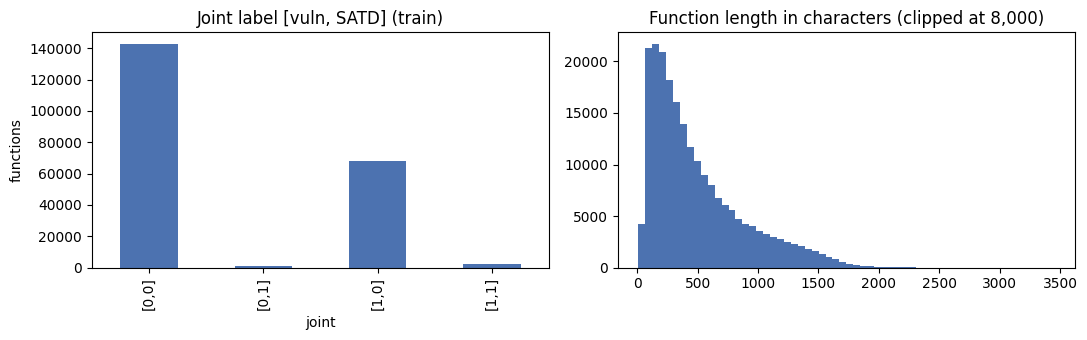

,in SATD comments %,in non-SATD comments %
todo,34.36,0.00
fixme,27.35,0.00
hack,5.54,0.00
xxx,21.39,0.02
workaround,0.79,0.03
temporary,0.54,0.03


In [5]:
eda = pd.DataFrame({
    split: {"functions": len(df),
            "vulnerable %": 100 * df.vuln.mean(),
            "SATD %": 100 * df.satd.mean(),
            "both %": 100 * ((df.vuln == 1) & (df.satd == 1)).mean(),
            "with comments %": 100 * df.has_comment.mean(),
            "median length (chars)": df.n_chars.median(),
            "projects": df.Projectname.nunique()}
    for split, df in [("train", train_df), ("test", test_df)]}).T.round(2)
display(eda); eda.to_csv(rpath("eda_summary.csv"))

joint = pd.crosstab(train_df.vuln, train_df.satd, margins=True)
joint.index = ["vuln=0", "vuln=1", "total"]; joint.columns = ["satd=0", "satd=1", "total"]
display(joint)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train_df.joint.map({0: "[0,0]", 1: "[0,1]", 2: "[1,0]", 3: "[1,1]"}).value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Joint label [vuln, SATD] (train)"); ax[0].set_ylabel("functions")
ax[1].hist(train_df.n_chars.clip(upper=8000), bins=60, color="#4C72B0")
ax[1].set_title("Function length in characters (clipped at 8,000)")
plt.tight_layout(); plt.savefig(rpath("eda.png"), dpi=150); plt.show()

kw = ["todo", "fixme", "hack", "xxx", "workaround", "temporary"]
satd_c = train_df[train_df.satd == 1].comments.str.lower()
non_c  = train_df[train_df.satd == 0].comments.str.lower()
kw_table = pd.DataFrame({"in SATD comments %": [100 * satd_c.str.contains(k).mean() for k in kw],
                         "in non-SATD comments %": [100 * non_c.str.contains(k).mean() for k in kw]}, index=kw).round(2)
display(kw_table); kw_table.to_csv(rpath("eda_satd_keywords.csv"))

## 4. Preprocessing: duplicates, leakage and splits


In [6]:
n_dup_train   = int(train_df.duplicated("Function").sum())
test_in_train = test_df.Function.isin(set(train_df.Function))
print(f"Exact duplicate functions inside train: {n_dup_train}")
print(f"Test functions that also appear in train: {int(test_in_train.sum())} ({100 * test_in_train.mean():.2f}%)")
clean_test_mask = (~test_in_train).values
tmp = dataset["train"].add_column("joint", train_df.joint.tolist()).class_encode_column("joint")
tmp = tmp.add_column("row_id", list(range(len(train_df))))
sp = tmp.train_test_split(test_size=0.1, stratify_by_column="joint", seed=SPLIT_SEED)
tr_idx = np.array(sp["train"]["row_id"]); va_idx = np.array(sp["test"]["row_id"])
print("train:", len(tr_idx), " validation:", len(va_idx))

val_df = train_df.iloc[va_idx].reset_index(drop=True)
y_val  = val_df[["vuln", "satd"]].values
y_test = test_df[["vuln", "satd"]].values

leak_set = set(test_df.Function) | set(val_df.Function)
tr_df = train_df.iloc[tr_idx]
tr_clean_idx = tr_df[~tr_df.Function.isin(leak_set)].drop_duplicates("Function").index.values
print("clean training rows for new runs:", len(tr_clean_idx))

Exact duplicate functions inside train: 808
Test functions that also appear in train: 251 (0.82%)


Stringifying the column:   0%|          | 0/214586 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/214586 [00:00<?, ? examples/s]

train: 193127  validation: 21459
clean training rows for new runs: 192125


In [7]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_ds(df, comments_first, tokenizer=tok, with_labels=True):
    d = Dataset.from_dict({"comments": df.comments.tolist(), "Function": df.Function.tolist(),
                           "labels": df[["vuln", "satd"]].astype(float).values.tolist()})
    def f(b):
        if comments_first:
            return tokenizer(b["comments"], b["Function"], truncation="longest_first", max_length=MAX_LEN)
        return tokenizer(b["Function"], truncation=True, max_length=MAX_LEN)
    d = d.map(f, batched=True, num_proc=2, remove_columns=["comments", "Function"])
    return d if with_labels else d.remove_columns(["labels"])

def training_args(out_dir, seed, epochs=1, batch=16, n_train=None):
    warm = int(0.06 * (n_train // batch) * epochs) if n_train else 0
    wanted = dict(output_dir=out_dir, per_device_train_batch_size=batch, per_device_eval_batch_size=64,
                  learning_rate=2e-5, num_train_epochs=epochs, weight_decay=0.01, warmup_steps=warm,
                  fp16=(DEVICE == "cuda"), save_strategy="no", logging_steps=200, report_to="none", seed=seed)
    ok = set(inspect.signature(TrainingArguments.__init__).parameters)
    return TrainingArguments(**{k: v for k, v in wanted.items() if k in ok})

class WeightedTrainer(Trainer):
    pos_weight = None
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        out = model(**inputs)
        pw = None if self.pos_weight is None else self.pos_weight.to(out.logits.device)
        loss = torch.nn.functional.binary_cross_entropy_with_logits(out.logits, labels.float(), pos_weight=pw)
        return (loss, out) if return_outputs else loss

def train_variant(df, comments_first, class_weights, seed, out_dir, epochs=1):
    set_seed(seed)
    ds = make_ds(df, comments_first)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, problem_type="multi_label_classification")
    tr = WeightedTrainer(model=model, args=training_args(out_dir, seed, epochs, n_train=len(ds)),
                         train_dataset=ds, data_collator=DataCollatorWithPadding(tok))
    if class_weights:   # w_j = sqrt(N_neg / N_pos)
        y = df[["vuln", "satd"]].values; pos = y.sum(0); neg = len(y) - pos
        tr.pos_weight = torch.tensor(np.sqrt(neg / pos), dtype=torch.float)
    t0 = time.time(); tr.train()
    return model, time.time() - t0

def predict_probs(model, ds, tokenizer=tok):
    tr = Trainer(model=model, args=training_args("/content/tmp_pred", SPLIT_SEED),
                 data_collator=DataCollatorWithPadding(tokenizer))
    t0 = time.time(); out = tr.predict(ds); dt = time.time() - t0
    logits = out.predictions[0] if isinstance(out.predictions, tuple) else out.predictions
    return 1 / (1 + np.exp(-logits)), dt

config.json:   0%|          | 0.00/498 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

In [8]:
GRID = np.round(np.arange(0.02, 0.96, 0.02), 2)
def tune_thresholds(probs, y):
    return [float(max(GRID, key=lambda t: f1_score(y[:, j], probs[:, j] > t, zero_division=0))) for j in range(2)]

def metrics(probs, y, ths):
    pred = (probs > np.array(ths)).astype(int); row = {}
    for j, t in enumerate(TASKS):
        row[f"{t} P"]        = precision_score(y[:, j], pred[:, j], zero_division=0)
        row[f"{t} R"]        = recall_score(y[:, j], pred[:, j], zero_division=0)
        row[f"{t} F1"]       = f1_score(y[:, j], pred[:, j], zero_division=0)
        row[f"{t} macro-F1"] = f1_score(y[:, j], pred[:, j], average="macro", zero_division=0)
        row[f"{t} MCC"]      = matthews_corrcoef(y[:, j], pred[:, j])
        row[f"{t} PR-AUC"]   = average_precision_score(y[:, j], probs[:, j])
    row["Mean F1"] = (row["Vulnerability F1"] + row["SATD F1"]) / 2   # competition metric
    return row

val_cf  = make_ds(val_df,  True,  with_labels=False)
test_cf = make_ds(test_df, True,  with_labels=False)
val_co  = make_ds(val_df,  False, with_labels=False)
test_co = make_ds(test_df, False, with_labels=False)

Map (num_proc=2):   0%|          | 0/21459 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/30655 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/21459 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/30655 [00:00<?, ? examples/s]

## 5. Approach 1: classical baseline (TF-IDF + logistic regression)


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

if os.path.exists(rpath("tfidf_test.npy")):
    tfidf_val, tfidf_test = np.load(rpath("tfidf_val.npy")), np.load(rpath("tfidf_test.npy"))
else:
    trd = train_df.loc[tr_clean_idx]
    t0 = time.time()
    vec = TfidfVectorizer(token_pattern=r"[A-Za-z_][A-Za-z0-9_]*", ngram_range=(1, 2), min_df=3,
                          max_features=300_000, sublinear_tf=True, lowercase=False)
    Xtr = vec.fit_transform(trd.Function); Xva = vec.transform(val_df.Function)
    clfs = []
    for col in ["vuln", "satd"]:
        clf = LogisticRegression(max_iter=2000, class_weight="balanced", solver="liblinear")
        clf.fit(Xtr, trd[col]); clfs.append(clf)
    timing["tfidf_train_s"] = time.time() - t0
    tfidf_val = np.column_stack([c.predict_proba(Xva)[:, 1] for c in clfs])
    t1 = time.time(); Xte = vec.transform(test_df.Function)
    tfidf_test = np.column_stack([c.predict_proba(Xte)[:, 1] for c in clfs])
    timing["tfidf_infer_s"] = time.time() - t1
    timing["tfidf_features"] = int(Xtr.shape[1]); save_timing()
    np.save(rpath("tfidf_val.npy"), tfidf_val); np.save(rpath("tfidf_test.npy"), tfidf_test)
print("TF-IDF done", {k: v for k, v in timing.items() if k.startswith("tfidf")})

TF-IDF done {'tfidf_train_s': 55.03367853164673, 'tfidf_infer_s': 3.1322038173675537, 'tfidf_features': 300000}


## 6. Approach 2: official CodeBERT baseline (reproduction)


In [10]:
baseline_ok = True
if os.path.exists(rpath("baseline_test.npy")):
    base_val, base_test = np.load(rpath("baseline_val.npy")), np.load(rpath("baseline_test.npy"))
else:
    try:
        try:
            btok = AutoTokenizer.from_pretrained(BASELINE_ID)
        except Exception:
            btok = tok
        bmodel = AutoModelForSequenceClassification.from_pretrained(BASELINE_ID)
        base_val, _ = predict_probs(bmodel, make_ds(val_df, False, btok, with_labels=False), btok)
        base_test, dt = predict_probs(bmodel, make_ds(test_df, False, btok, with_labels=False), btok)
        timing["baseline_infer_s"] = dt; save_timing()
        np.save(rpath("baseline_val.npy"), base_val); np.save(rpath("baseline_test.npy"), base_test)
        del bmodel; torch.cuda.empty_cache()
    except Exception as e:
        baseline_ok = False
        print("Could not load the official baseline:", e)
        from huggingface_hub import list_repo_files
        print("Files in the baseline repo:", list_repo_files(BASELINE_ID))
print("baseline available:", baseline_ok)

baseline available: True


## 7. Approach 3: our multitask CodeBERT (comments-first + class weights + per-label thresholds)


In [11]:
if os.path.exists(os.path.join(MAIN_CKPT, "config.json")):
    main_model = AutoModelForSequenceClassification.from_pretrained(MAIN_CKPT)
    timing.setdefault("main_train_s", 4824.1)
else:
    main_model, t = train_variant(train_df.iloc[tr_idx], True, True, SPLIT_SEED, "/content/main_out")
    timing["main_train_s"] = t
    main_model.save_pretrained(MAIN_CKPT); tok.save_pretrained(MAIN_CKPT)
save_timing()

if os.path.exists(rpath("main_test.npy")):
    main_val, main_test = np.load(rpath("main_val.npy")), np.load(rpath("main_test.npy"))
else:
    main_val, _ = predict_probs(main_model, val_cf)
    main_test, dt = predict_probs(main_model, test_cf)
    timing["main_infer_s"] = dt; save_timing()
    np.save(rpath("main_val.npy"), main_val); np.save(rpath("main_test.npy"), main_test)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## 8. Evaluation (RQ1)


In [12]:
rows, approaches = [], {"TF-IDF + LR": (tfidf_val, tfidf_test)}
if baseline_ok:
    approaches["Official baseline"] = (base_val, base_test)
approaches["Ours"] = (main_val, main_test)

thresholds = {}
for name, (pv, pt) in approaches.items():
    modes = [("t=0.5", [0.5, 0.5]), ("tuned t", tune_thresholds(pv, y_val))]
    if name == "TF-IDF + LR":
        modes = modes[1:]
    for mode, ths in modes:
        thresholds[f"{name} ({mode})"] = ths
        for subset, mask in [("test", slice(None)), ("clean test", clean_test_mask)]:
            r = metrics(pt[mask], y_test[mask], ths)
            rows.append({"Approach": f"{name} ({mode})", "Split": subset,
                         "thresholds": str([round(t, 2) for t in ths]), **r})
results = pd.DataFrame(rows)
results.to_csv(rpath("results_main.csv"), index=False)

show = ["Approach", "Split", "thresholds", "Vulnerability P", "Vulnerability R", "Vulnerability F1",
        "SATD P", "SATD R", "SATD F1", "Mean F1"]
display(results[results.Split == "test"][show].round(3))
display(results[results.Split == "test"][["Approach", "Vulnerability macro-F1", "Vulnerability MCC", "Vulnerability PR-AUC",
                                          "SATD macro-F1", "SATD MCC", "SATD PR-AUC"]].round(3))
display(results[results.Split == "clean test"][show].round(3))
json.dump(thresholds, open(rpath("thresholds.json"), "w"), indent=2)

,Approach,Split,thresholds,Vulnerability P,Vulnerability R,Vulnerability F1,SATD P,SATD R,SATD F1,Mean F1
0,TF-IDF + LR (tuned t),test,"[0.48, 0.76]",0.694,0.809,0.748,0.920,0.796,0.854,0.801
2,Official baseline (t=0.5),test,"[0.5, 0.5]",0.943,0.935,0.939,0.978,0.802,0.881,0.910
4,Official baseline (tuned t),test,"[0.34, 0.02]",0.942,0.936,0.939,0.978,0.802,0.881,0.910
6,Ours (t=0.5),test,"[0.5, 0.5]",0.924,0.926,0.925,0.987,0.877,0.929,0.927
8,Ours (tuned t),test,"[0.5, 0.04]",0.924,0.926,0.925,0.971,0.877,0.922,0.923


,Approach,Vulnerability macro-F1,Vulnerability MCC,Vulnerability PR-AUC,SATD macro-F1,SATD MCC,SATD PR-AUC
0,TF-IDF + LR (tuned t),0.804,0.614,0.845,0.926,0.854,0.867
2,Official baseline (t=0.5),0.955,0.909,0.985,0.940,0.884,0.817
4,Official baseline (tuned t),0.955,0.909,0.985,0.940,0.884,0.817
6,Ours (t=0.5),0.944,0.888,0.979,0.964,0.929,0.890
8,Ours (tuned t),0.944,0.888,0.979,0.960,0.922,0.890


,Approach,Split,thresholds,Vulnerability P,Vulnerability R,Vulnerability F1,SATD P,SATD R,SATD F1,Mean F1
1,TF-IDF + LR (tuned t),clean test,"[0.48, 0.76]",0.694,0.809,0.747,0.921,0.796,0.854,0.801
3,Official baseline (t=0.5),clean test,"[0.5, 0.5]",0.943,0.935,0.939,0.978,0.802,0.882,0.910
5,Official baseline (tuned t),clean test,"[0.34, 0.02]",0.943,0.936,0.939,0.978,0.802,0.882,0.910
7,Ours (t=0.5),clean test,"[0.5, 0.5]",0.924,0.927,0.925,0.987,0.878,0.929,0.927
9,Ours (tuned t),clean test,"[0.5, 0.04]",0.924,0.927,0.925,0.971,0.878,0.922,0.924


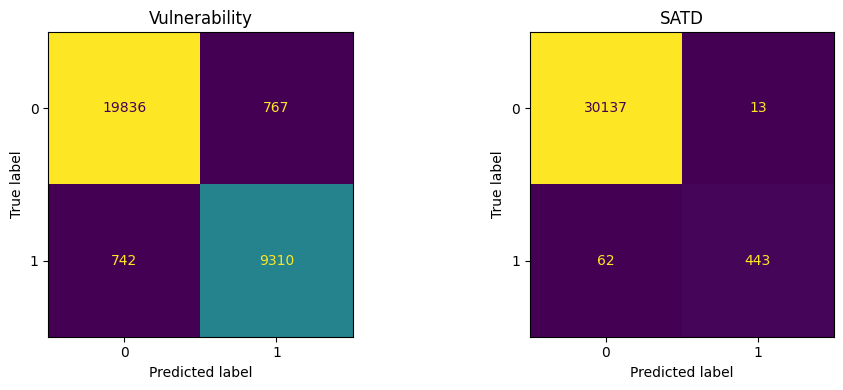

In [13]:
ths_main = thresholds["Ours (tuned t)"]
pred_main = (main_test > np.array(ths_main)).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for j, name in enumerate(TASKS):
    ConfusionMatrixDisplay(confusion_matrix(y_test[:, j], pred_main[:, j])).plot(ax=axes[j], colorbar=False, values_format="d")
    axes[j].set_title(name)
plt.tight_layout(); plt.savefig(rpath("confusion_matrices.png"), dpi=150); plt.show()

### 8.1 Statistical tests


In [14]:
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_test(pa, pb, y):
    a_ok, b_ok = pa == y, pb == y
    b = int((a_ok & ~b_ok).sum()); c = int((~a_ok & b_ok).sum())
    r = mcnemar([[0, b], [c, 0]], exact=False, correction=True)
    return b, c, float(r.statistic), float(r.pvalue)

def fast_f1(y, p):
    tp = (y & p).sum(0); fp = (~y & p).sum(0); fn = (y & ~p).sum(0)
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def bootstrap_diff(pa, pb, y, n=1000, seed=0):
    rng = np.random.default_rng(seed); y = y.astype(bool); pa = pa.astype(bool); pb = pb.astype(bool)
    diffs = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        diffs.append(fast_f1(y[i], pa[i]).mean() - fast_f1(y[i], pb[i]).mean())
    return float(np.mean(diffs)), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

def preds(name):
    pv, pt = approaches[name.split(" (")[0]]
    return (pt > np.array(thresholds[name])).astype(int)

comparisons = [("Ours (tuned t)", "TF-IDF + LR (tuned t)"), ("Ours (tuned t)", "Ours (t=0.5)")]
if baseline_ok:
    comparisons = [("Ours (tuned t)", "Official baseline (t=0.5)"),
                   ("Ours (tuned t)", "Official baseline (tuned t)")] + comparisons
stat_rows = []
for a, b in comparisons:
    pa, pb = preds(a), preds(b)
    d, lo, hi = bootstrap_diff(pa, pb, y_test)
    for j, t in enumerate(TASKS):
        nb, nc, chi2, p = mcnemar_test(pa[:, j], pb[:, j], y_test[:, j])
        stat_rows.append({"A": a, "B": b, "Task": t, "A right, B wrong": nb, "A wrong, B right": nc,
                          "odds ratio": round(nb / max(nc, 1), 2), "chi2": round(chi2, 2), "p-value": p,
                          "mean-F1 diff (A-B)": round(d, 4), "95% CI": f"[{lo:.4f}, {hi:.4f}]"})
stats = pd.DataFrame(stat_rows); stats.to_csv(rpath("statistical_tests.csv"), index=False)
display(stats)

,A,B,Task,"A right, B wrong","A wrong, B right",odds ratio,chi2,p-value,mean-F1 diff (A-B),95% CI
0,Ours (tuned t),Official baseline (t=0.5),Vulnerability,429,716,0.60,71.44,2.861732e-17,0.0135,"[0.0058, 0.0219]"
1,Ours (tuned t),Official baseline (t=0.5),SATD,42,8,5.25,21.78,3.057710e-06,0.0135,"[0.0058, 0.0219]"
2,Ours (tuned t),Official baseline (tuned t),Vulnerability,428,715,0.60,71.56,2.686061e-17,0.0135,"[0.0057, 0.0219]"
3,Ours (tuned t),Official baseline (tuned t),SATD,42,8,5.25,21.78,3.057710e-06,0.0135,"[0.0057, 0.0219]"
4,Ours (tuned t),TF-IDF + LR (tuned t),Vulnerability,4782,795,6.02,2848.88,0.000000e+00,0.1231,"[0.1132, 0.1332]"
5,Ours (tuned t),TF-IDF + LR (tuned t),SATD,76,13,5.85,43.19,4.964825e-11,0.1231,"[0.1132, 0.1332]"
6,Ours (tuned t),Ours (t=0.5),Vulnerability,0,0,0.00,inf,0.000000e+00,-0.0034,"[-0.0061, -0.0011]"
7,Ours (tuned t),Ours (t=0.5),SATD,0,7,0.00,5.14,2.334220e-02,-0.0034,"[-0.0061, -0.0011]"


## 9. Ablation study with 3 seeds (RQ2)


In [15]:
variants = {"V0 code only, plain loss": (False, False),
            "V1 + comments first": (True, False),
            "V2 + comments first + class weights": (True, True)}
_, val_small_idx = train_test_split(np.arange(len(val_df)), test_size=5000, stratify=val_df.joint, random_state=0)
val_small = val_df.iloc[val_small_idx].reset_index(drop=True); y_val_small = val_small[["vuln", "satd"]].values
val_small_ds = {True: make_ds(val_small, True, with_labels=False), False: make_ds(val_small, False, with_labels=False)}
test_ds = {True: test_cf, False: test_co}
tr_clean_df = train_df.loc[tr_clean_idx]

abl_rows = []
for seed in SEEDS:
    sub, _ = train_test_split(tr_clean_df, train_size=ABLATION_FRAC, stratify=tr_clean_df.joint, random_state=seed)
    for vname, (cf, cw) in variants.items():
        f = rpath(f"ablation_{vname.split()[0]}_seed{seed}.json")
        if os.path.exists(f):
            res = json.load(open(f))
        else:
            print(f"Training {vname}, seed {seed} on {len(sub)} functions ...")
            model, t = train_variant(sub, cf, cw, seed, "/content/abl_out")
            pv, _ = predict_probs(model, val_small_ds[cf]); pt, dt = predict_probs(model, test_ds[cf])
            ths = tune_thresholds(pv, y_val_small)
            res = {"variant": vname, "seed": seed, "train_s": t, "infer_s": dt, "tuned_ths": ths,
                   "t=0.5": metrics(pt, y_test, [0.5, 0.5]), "tuned t": metrics(pt, y_test, ths)}
            json.dump(res, open(f, "w"), indent=2)
            del model; torch.cuda.empty_cache()
        for mode in ["t=0.5", "tuned t"]:
            abl_rows.append({"Variant": vname, "Thresholds": mode, "seed": seed, **res[mode]})

abl = pd.DataFrame(abl_rows); abl.to_csv(rpath("ablation_runs.csv"), index=False)
cols = ["Vulnerability F1", "SATD F1", "SATD R", "Mean F1"]
summary = abl.groupby(["Variant", "Thresholds"])[cols].agg(["mean", "std"]).round(3)
summary.to_csv(rpath("ablation_summary.csv")); display(summary)

Map (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

Training V0 code only, plain loss, seed 44 on 19212 functions ...


Map (num_proc=2):   0%|          | 0/19212 [00:00<?, ? examples/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (12 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: microsoft/codebert-base
Key                        | Status     | 
---------------------------+------------+-
pooler.dense.weight        | UNEXPECTED | 
pooler.dense.bias          | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
200,0.544761
400,0.409786
600,0.274819
800,0.265756
1000,0.229397
1200,0.229368


Vulnerability F1         \
                                                           mean    std   
Variant                             Thresholds                           
V0 code only, plain loss            t=0.5                 0.824  0.008   
                                    tuned t               0.821  0.009   
V1 + comments first                 t=0.5                 0.823  0.009   
                                    tuned t               0.823  0.010   
V2 + comments first + class weights t=0.5                 0.823  0.017   
                                    tuned t               0.823  0.019   

                                               SATD F1        SATD R         \
                                                  mean    std   mean    std   
Variant                             Thresholds                                
V0 code only, plain loss            t=0.5        0.215  0.373  0.160  0.277   
                                    tuned t      0.325  0.382  0.593  0.191   
V1 + comments first                 t=0.5        0.256  0.443  0.209  0.362   
                                    tuned t      0.426  0.376  0.586  0.184   
V2 + comments first + class weights t=0.5        0.889  0.002  0.830  0.003   
                                    tuned t      0.891  0.004  0.830  0.005   

                                               Mean F1         
                                                  mean    std  
Variant                             Thresholds                 
V0 code only, plain loss            t=0.5        0.519  0.190  
                                    tuned t      0.573  0.196  
V1 + comments first                 t=0.5        0.539  0.225  
                                    tuned t      0.624  0.193  
V2 + comments first + class weights t=0.5        0.856  0.008  
                                    tuned t      0.857  0.010

## 10. Error analysis (RQ3)

In [16]:
test_tokens = np.array([len(x) for x in tok(test_df.Function.tolist())["input_ids"]])
truncated = test_tokens > MAX_LEN
has_kw = test_df.comments.str.lower().apply(lambda c: any(k in c for k in kw)).values

err_tab = []
for j, t in enumerate(TASKS):
    wrong = pred_main[:, j] != y_test[:, j]
    for label, mask in [("all", np.ones(len(y_test), bool)), ("truncated (>512 tokens)", truncated),
                        ("not truncated", ~truncated), ("has comments", test_df.has_comment.values),
                        ("no comments", ~test_df.has_comment.values)]:
        err_tab.append({"Task": t, "Subset": label, "functions": int(mask.sum()),
                        "error rate %": round(100 * wrong[mask].mean(), 2)})
err_tab = pd.DataFrame(err_tab); err_tab.to_csv(rpath("error_rates_by_subset.csv"), index=False)
display(err_tab)

satd_fn = (y_test[:, 1] == 1) & (pred_main[:, 1] == 0)
satd_fp = (y_test[:, 1] == 0) & (pred_main[:, 1] == 1)
print(f"SATD misses with a TODO/FIXME-style keyword: {has_kw[satd_fn].mean():.0%} of {satd_fn.sum()}")
print(f"SATD false alarms with such a keyword:       {has_kw[satd_fp].mean():.0%} of {satd_fp.sum()}")

rng, err_rows = np.random.default_rng(0), []
for j, t in enumerate(TASKS):
    wrong = np.where(pred_main[:, j] != y_test[:, j])[0]
    for i in rng.choice(wrong, size=min(15, len(wrong)), replace=False):
        r = test_df.iloc[i]
        err_rows.append({"task": t, "row": int(i),
                         "type": "FN (missed)" if y_test[i, j] == 1 else "FP (false alarm)",
                         "prob": round(float(main_test[i, j]), 3), "tokens": int(test_tokens[i]),
                         "satd keyword": bool(has_kw[i]), "comments": r.comments[:300],
                         "code (start)": r.Function[:500], "category (manual)": ""})
err_df = pd.DataFrame(err_rows); err_df.to_csv(rpath("error_analysis_sample.csv"), index=False)
pd.set_option("display.max_colwidth", 200)
display(err_df.drop(columns=["code (start)"]))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (791 > 512). Running this sequence through the model will result in indexing errors


,Task,Subset,functions,error rate %
0,Vulnerability,all,30655,4.92
1,Vulnerability,truncated (>512 tokens),3249,11.73
2,Vulnerability,not truncated,27406,4.12
3,Vulnerability,has comments,4423,8.79
4,Vulnerability,no comments,26232,4.27
5,SATD,all,30655,0.24
6,SATD,truncated (>512 tokens),3249,0.62
7,SATD,not truncated,27406,0.20
8,SATD,has comments,4423,0.66
9,SATD,no comments,26232,0.18


SATD misses with a TODO/FIXME-style keyword: 2% of 62
SATD false alarms with such a keyword:       0% of 13


,task,row,type,prob,tokens,satd keyword,comments,category (manual)
0,Vulnerability,11447,FP (false alarm),0.570,866,False,"If not found, use SGRBG10 as default The preview module output size is configurable through the * averager (horizontal scaling by 1/1, 1/2, 1/4 or 1/8). This * is not supported yet, hardcode the o...",
1,Vulnerability,25702,FN (missed),0.051,357,False,,
2,Vulnerability,30187,FP (false alarm),0.990,373,True,XXX unhandled,
3,Vulnerability,25012,FN (missed),0.055,393,False,,
4,Vulnerability,12708,FN (missed),0.076,544,False,eeprom exist maybe MAC-address is from BIOS,
5,Vulnerability,29531,FN (missed),0.134,93,False,,
6,Vulnerability,29825,FN (missed),0.036,78,False,,
7,Vulnerability,1616,FN (missed),0.161,572,False,"Use default ctefx.bin if no alt firmware is detected, or if none * exists for your particular codec.",
8,Vulnerability,20159,FP (false alarm),0.998,107,False,,
9,Vulnerability,20266,FP (false alarm),0.854,178,False,,


## 11. Runtime and computational cost

In [17]:
from torch.utils.flop_counter import FlopCounterMode

def gflops_per_sample(model, tokenizer, comments_first, n=200):
    model = model.to(DEVICE).eval(); total = 0
    for _, r in test_df.sample(n, random_state=0).iterrows():
        if comments_first:
            enc = tokenizer(r.comments, r.Function, truncation="longest_first", max_length=MAX_LEN, return_tensors="pt")
        else:
            enc = tokenizer(r.Function, truncation=True, max_length=MAX_LEN, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        with torch.no_grad(), FlopCounterMode(display=False) as fc:
            model(**enc)
        total += fc.get_total_flops()
    return total / n / 1e9

if "main_gflops" not in timing:
    timing["main_gflops"] = gflops_per_sample(main_model, tok, True)
    timing["codeonly_gflops"] = gflops_per_sample(main_model, tok, False)   # same network, code-only input
    save_timing()

n_test = len(test_df)
cost = [{"Approach": "TF-IDF + LR", "parameters": 2 * timing.get("tfidf_features", 0),
         "train time (min)": timing.get("tfidf_train_s", np.nan) / 60,
         "inference (ms/function)": 1000 * timing.get("tfidf_infer_s", np.nan) / n_test, "GFLOPs/function": np.nan}]
if baseline_ok:
    cost.append({"Approach": "Official baseline", "parameters": sum(p.numel() for p in main_model.parameters()),
                 "train time (min)": np.nan,
                 "inference (ms/function)": 1000 * timing.get("baseline_infer_s", np.nan) / n_test,
                 "GFLOPs/function": timing["codeonly_gflops"]})
cost.append({"Approach": "Ours", "parameters": sum(p.numel() for p in main_model.parameters()),
             "train time (min)": timing["main_train_s"] / 60,
             "inference (ms/function)": 1000 * timing.get("main_infer_s", np.nan) / n_test,
             "GFLOPs/function": timing["main_gflops"]})
cost = pd.DataFrame(cost).round(2); cost.to_csv(rpath("cost.csv"), index=False); display(cost)
print("Hardware:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")

,Approach,parameters,train time (min),inference (ms/function),GFLOPs/function
0,TF-IDF + LR,600000,0.92,0.10,NaN
1,Official baseline,124647170,NaN,7.75,38.50
2,Ours,124647170,80.40,8.06,39.34


Hardware: Tesla T4


## 12. Conclusions


In [18]:
print("Saved files:")
for f in sorted(os.listdir(RESULTS_DIR)):
    print(" ", f)

Saved files:
  ablation_V0_seed42.json
  ablation_V0_seed43.json
  ablation_V0_seed44.json
  ablation_V1_seed42.json
  ablation_V1_seed43.json
  ablation_V1_seed44.json
  ablation_V2_seed42.json
  ablation_V2_seed43.json
  ablation_V2_seed44.json
  ablation_runs.csv
  ablation_summary.csv
  baseline_test.npy
  baseline_val.npy
  confusion_matrices.png
  cost.csv
  eda.png
  eda_satd_keywords.csv
  eda_summary.csv
  error_analysis_sample.csv
  error_rates_by_subset.csv
  main_test.npy
  main_val.npy
  results_main.csv
  statistical_tests.csv
  tfidf_test.npy
  tfidf_val.npy
  thresholds.json
  timing.json
